# Tutorial 2: Na3OCl(100) | Na(100) with MACE-MP-0, analysis notebook

The system of the VASP tutorial in `../Antiperovskites`, with the MACE-MP-0 foundation model (small) instead of DFT.
Running the workflow takes about a minute on a CPU and needs `pip install "interfacer[mace]"`; if `OUTPUT/results.json`
exists already (e.g. from `./run.sh`), the notebook only analyses it.

In [1]:
import os
import warnings

for w in ("Environment variable TORCH_FORCE", "`torch.jit", "Occupancies"):   # harmless notes of torch/ASE
    warnings.filterwarnings("ignore", message=w)
RUN = not os.path.exists("OUTPUT/results.json")   # set to True to re-run
if RUN:
    from interfacer.cli import main
    main(["--input", "input.toml", "-q"])

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.


Using Materials Project MACE for MACECalculator with /root/.cache/mace/20231210mace128L0_energy_epoch249model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


## Results

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
from ase.io import read
from ase.visualize.plot import plot_atoms

J = 0.160217663   # eV/nm^2 -> J/m^2
res = json.load(open("OUTPUT/results.json"))
print("Bulk energies: %.4f and %.4f eV/atom" % (res["E_bulk1"], res["E_bulk2"]))
print("Surfaces:", res["miller1"], "|", res["miller2"])
for n in (1, 2):
    for s in res["slabs%d" % n]:
        print("  slab %d %-12s %3d atoms  SFE = %6.2f eV/nm^2 = %.2f J/m^2" % (n, s["name"], s["natoms"], s["sfe"], s["sfe"] * J))
for r in res["interfaces"]:
    print("\nInterface %s (%s | %s)" % (r["name"], r["slab1"], r["slab2"]))
    print("  misfit %.2f%% -> %.2f%% after alignment, area %.1f A^2" % (100 * r["misfit_before"], 100 * r["misfit_after"], r["area"]))
    print("  W_surf = %.2f and %.2f J/m^2, separation %.2f A, %d interface(s) in the cell"
          % (r["W_surf1"] * J, r["W_surf2"] * J, r["sep"], r["n_interfaces"]))
    print("  W_ad = %.2f J/m^2, gamma_int = %.2f J/m^2" % (r["W_ad"] * J, r["gamma_int"] * J))

Bulk energies: -3.6022 and -1.3068 eV/atom
Surfaces: [1, 0, 0] | [1, 0, 0]
  slab 1 slab1_cut0    20 atoms  SFE =   2.09 eV/nm^2 = 0.33 J/m^2
  slab 2 slab2_cut0    12 atoms  SFE =   1.53 eV/nm^2 = 0.25 J/m^2

Interface interface_cuts_0_0 (slab1_cut0 | slab2_cut0)
  misfit 7.41% -> 3.73% after alignment, area 85.7 A^2
  W_surf = 0.33 and 0.25 J/m^2, separation 3.00 A, 2 interface(s) in the cell
  W_ad = 0.42 J/m^2, gamma_int = 0.16 J/m^2


## Separation scan

Rigid slabs at the initial registry; the interface is then optimised with a fixed cell, keeping this separation.

best separation: 3.00 A


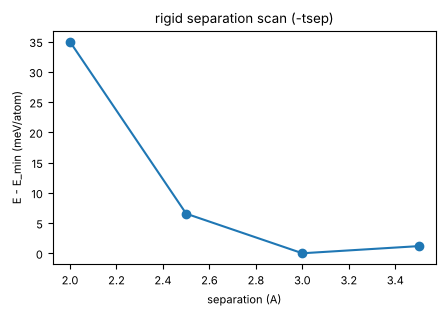

In [3]:
d = np.loadtxt("OUTPUT/conv_sep.csv", delimiter=",", skiprows=1)
plt.figure(figsize=(4.5, 3.2))
plt.plot(d[:, 0], (d[:, 1] - d[:, 1].min()) * 1000, "o-")
plt.xlabel("separation (A)")
plt.ylabel("E - E_min (meV/atom)")
plt.title("rigid separation scan (-tsep)")
plt.tight_layout()
print("best separation: %.2f A" % d[np.argmin(d[:, 1]), 0])

## Structure

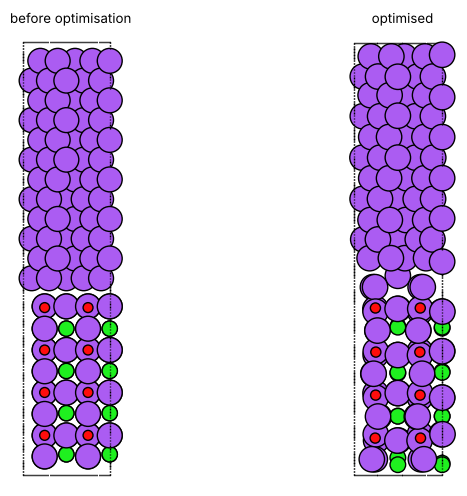

In [4]:
def show(path, ax, title, rotation="-90x"):
    atoms = read(path)
    plot_atoms(atoms, ax, rotation=rotation, radii=0.8)
    ax.set_title(title)
    ax.set_axis_off()

name = res["interfaces"][0]["name"]
fig, axes = plt.subplots(1, 2, figsize=(9, 5))
show("OUTPUT/%s.xyz" % name.replace("interface_cuts", "interface-pre_opt_cuts"), axes[0], "before optimisation")
show("OUTPUT/%s_opted.xyz" % name, axes[1], "optimised")
plt.tight_layout()

## Discussion

* The Na3OCl(100) slab with an even number of layers (`cr1 = 4`) is stoichiometric, so W_surf is its surface energy.
* W_ad is the energy (per area) needed to separate the interface into two free surfaces; the interface energy follows
  from the Dupré relation.
* The foundation model is a quick pre-screen. For production results use a larger model (`mlip_model =
  "medium-mpa-0"`) or DFT (`../Antiperovskites`, `-prog vasp`) on the selected structures.

In [5]:
r = res["interfaces"][0]
print("W_ad = %.2f J/m^2 (%.2f eV/nm^2), gamma_int = %.2f J/m^2" % (r["W_ad"] * J, r["W_ad"], r["gamma_int"] * J))

W_ad = 0.42 J/m^2 (2.65 eV/nm^2), gamma_int = 0.16 J/m^2
